# 05. Дополнительные модели

Проверка: можно ли улучшить финальную модель (Ridge + TF-IDF из ноутбука 03), если взять
другие семейства моделей на тех же признаках.

| Модель | Идея |
|---|---|
| Ridge (финальная) | линейная модель, штраф за большие веса |
| Huber | линейная модель, устойчивая к выбросам: большие ошибки штрафуются слабее |
| Linear SVR | линейная модель, оптимизирует абсолютную ошибку (как MAE) |
| kNN | прогноз как зарплата 15 самых похожих по тексту объявлений |
| LightGBM на всех признаках | градиентный бустинг на one-hot + TF-IDF (тысячи разреженных признаков) |
| CatBoost с текстом, MAE | бустинг со встроенной обработкой текста, оптимизирует абсолютную ошибку |
| Смесь Ridge + CatBoost | среднее прогнозов двух лучших моделей разного типа |

Все модели сравниваются на той же 5-кратной групповой кросс-валидации, лучшие проверяются на тесте.

> **Время:** CatBoost с текстом обучается долго (несколько минут на фолд). Чтобы пропустить медленные
> модели, поставьте `RUN_SLOW = False`.

In [1]:
import sys, json, time, warnings
sys.path.insert(0, "../src")
import prep

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.svm import LinearSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
import lightgbm as lgb
from catboost import CatBoostRegressor

RUN_SLOW = True
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"

meta = json.load(open("../models/final_model_meta.json"))
p, COLS = meta["params"], meta["features"]
C, N, B = prep.CAT_FEATURES, prep.NUM_FEATURES, prep.BOOL_FEATURES

data = prep.labeled(prep.load())
train, test = prep.split(data)
folds = prep.cv_folds(train)

def features():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=p["min_freq"]), C),
        ("num", StandardScaler(), N + B),
        ("t", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, ngram_range=(1, p["word_ngram"]),
                              max_features=p["word_max"]), "full"),
        ("ti", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, analyzer="char_wb",
                               ngram_range=(2, p["char_max"])), "title"),
    ], transformer_weights={"ti": p["title_weight"]})

In [2]:
class OnFeatures:
    """Любая sklearn-модель поверх общих признаков."""
    def __init__(self, model): self.model = model
    def fit(self, d): self.pipe = make_pipeline(features(), self.model).fit(d[COLS], d.y); return self
    def predict(self, d): return self.pipe.predict(d[COLS])

class LGBSparse:
    def fit(self, d):
        self.f = features(); X = self.f.fit_transform(d[COLS]).astype(np.float32)
        self.m = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=31, min_child_samples=15,
                                   colsample_bytree=0.3, objective="huber", alpha=0.5,
                                   random_state=42, verbose=-1).fit(X, d.y)
        return self
    def predict(self, d): return self.m.predict(self.f.transform(d[COLS]).astype(np.float32))

class CBText:
    cols = C + N + B + ["full", "title"]
    def fit(self, d):
        self.m = CatBoostRegressor(iterations=800, learning_rate=0.08, depth=6, loss_function="MAE", verbose=0,
                                   random_seed=42, cat_features=C, text_features=["full", "title"]
                                   ).fit(d[self.cols], d.y)
        return self
    def predict(self, d): return self.m.predict(d[self.cols])

class Blend:
    def __init__(self, makers, weights): self.makers, self.weights = makers, weights
    def fit(self, d): self.models = [mk().fit(d) for mk in self.makers]; return self
    def predict(self, d): return sum(w * m.predict(d) for w, m in zip(self.weights, self.models))

ridge = lambda: OnFeatures(Ridge(alpha=p["alpha"]))
MODELS = {
    "Ridge (финальная)": (ridge, False),
    "Huber": (lambda: OnFeatures(HuberRegressor(alpha=1e-4, epsilon=1.35, max_iter=300)), False),
    "Linear SVR": (lambda: OnFeatures(LinearSVR(C=0.1, epsilon=0.0, max_iter=5000, random_state=0)), False),
    "kNN (15 похожих)": (lambda: OnFeatures(KNeighborsRegressor(n_neighbors=15, weights="distance", metric="cosine")), False),
    "LightGBM на всех признаках": (lambda: LGBSparse(), False),
    "CatBoost с текстом, MAE": (lambda: CBText(), True),
    "Смесь Ridge + CatBoost": (lambda: Blend([ridge, lambda: CBText()], [0.5, 0.5]), True),
}

## 1. Кросс-валидация

In [3]:
rows = []
for name, (make, slow) in MODELS.items():
    if slow and not RUN_SLOW:
        continue
    t0 = time.time()
    for k, (a, b) in enumerate(folds):
        m = make().fit(train.iloc[a])
        rows.append({"модель": name, "фолд": k, **prep.metrics(train.iloc[b].y.values, m.predict(train.iloc[b]))})
    print(f"{name:28s} {time.time() - t0:6.0f} с", flush=True)

cv = pd.DataFrame(rows)
summary = cv.groupby("модель").agg(MAE=("MAE, сом", "mean"), MAE_std=("MAE, сом", "std"),
                                   медианная=("медианная ошибка, сом", "mean"),
                                   R2=("R² (log)", "mean")).sort_values("MAE")
summary.style.format({"MAE": "{:,.0f}", "MAE_std": "±{:,.0f}", "медианная": "{:,.0f}", "R2": "{:.3f}"})

Ridge (финальная)                 5 с


Huber                            22 с


Linear SVR                        5 с


kNN (15 похожих)                  6 с


LightGBM на всех признаках      154 с


CatBoost с текстом, MAE         962 с


Смесь Ridge + CatBoost          810 с


,MAE,MAE_std,медианная,R2
модель,,,,
Смесь Ridge + CatBoost,"15,534",±795,"8,969",0.410
Ridge (финальная),"15,610",±585,"9,412",0.407
Linear SVR,"15,786",±630,"9,264",0.386
"CatBoost с текстом, MAE","16,138",±988,"9,259",0.359
LightGBM на всех признаках,"16,331",±960,"10,077",0.355
Huber,"16,528",±833,"10,308",0.317
kNN (15 похожих),"16,841",±554,"10,419",0.321


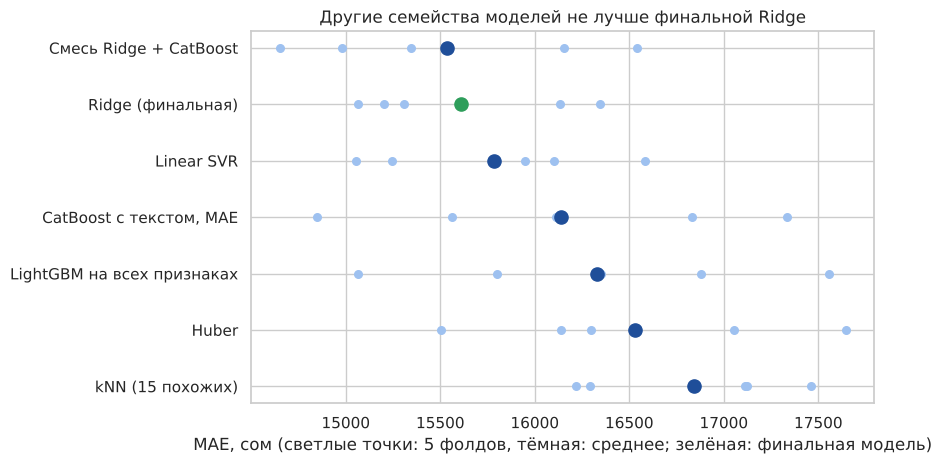

In [4]:
order = summary.index[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, name in enumerate(order):
    v = cv.loc[cv["модель"] == name, "MAE, сом"]
    ax.scatter(v, [i] * len(v), color="#9ec1f0", s=30)
    ax.scatter(v.mean(), i, color="#1f4e99" if "финальная" not in name else "#2e9e5b", s=90, zorder=3)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("MAE, сом (светлые точки: 5 фолдов, тёмная: среднее; зелёная: финальная модель)")
ax.set_title("Другие семейства моделей не лучше финальной Ridge")
plt.tight_layout(); plt.savefig(FIG + "05_more_models.png", dpi=150); plt.show()

## 2. Проверка на тесте (три лучшие модели)

In [5]:
top = [n for n in summary.index[:3]]
rows = []
for name in top:
    t0 = time.time()
    m = MODELS[name][0]().fit(train)
    rows.append({"модель": name, **prep.metrics(test.y.values, m.predict(test)), "время обучения, с": time.time() - t0})
pd.DataFrame(rows).set_index("модель").style.format({"MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}",
    "MAPE, %": "{:.1f}", "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}", "время обучения, с": "{:.0f}"})

,"MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log),"время обучения, с"
модель,,,,,,
Смесь Ridge + CatBoost,"15,755","9,126",33.4,44%,0.375,167
Ridge (финальная),"15,763","9,500",34.2,43%,0.377,1
Linear SVR,"16,291","9,642",35.1,42%,0.324,1


## Выводы

| Модель | MAE, кросс-валидация | MAE, тест | время обучения |
|---|---|---|---|
| Смесь Ridge + CatBoost | 15 534 ± 795 | 15 755 | ~3 мин |
| **Ridge (финальная)** | **15 610 ± 585** | **15 763** | **~1 с** |
| Linear SVR | 15 786 ± 630 | 16 291 | ~1 с |
| CatBoost с текстом, MAE | 16 138 ± 988 | | ~3 мин |
| LightGBM на всех признаках | 16 331 ± 960 | | ~30 с |
| Huber | 16 528 ± 833 | | ~5 с |
| kNN (15 похожих объявлений) | 16 841 ± 554 | | ~1 с |

1. **Ни одно семейство моделей не лучше финальной Ridge заметно.** Смесь Ridge + CatBoost выигрывает
   всего 76 сом на кросс-валидации и 8 сом на тесте: это в 10 раз меньше разброса между фолдами.
2. **Бустинг (CatBoost, LightGBM) на разреженных текстовых признаках работает хуже линейной модели.**
   При ~4 700 обучающих объявлениях и десятках тысяч слов линейная модель с регуляризацией устойчивее.
3. **kNN хуже всех:** «похожие по тексту объявления» платят слишком по-разному, что подтверждает
   высокий шум внутри одинаковых профессий.
4. **Решение:** финальной остаётся Ridge + TF-IDF: та же точность, обучение за секунду, понятные веса слов.
   Предел качества задаёт шум в данных, а не выбор модели.
